In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

In [2]:
df = pd.read_csv(r"C:\Users\Lenovo\Downloads\house_prices.csv")
df

,House_ID,Area_SqFt,Bedrooms,Bathrooms,Price_USD
0,H1001,3974,5,4.8,1010000
1,H1002,4307,6,5.0,867000
2,H1003,1660,3,2.2,396000
3,H1004,2094,2,1.5,482000
4,H1005,1930,3,2.2,521000
...,...,...,...,...,...
95,H1096,2379,3,2.7,667000
96,H1097,961,2,1.5,243000
97,H1098,1001,1,1.3,253000
98,H1099,2781,4,3.0,610000


In [3]:
df.columns

Index(['House_ID', 'Area_SqFt', 'Bedrooms', 'Bathrooms', 'Price_USD'], dtype='str')

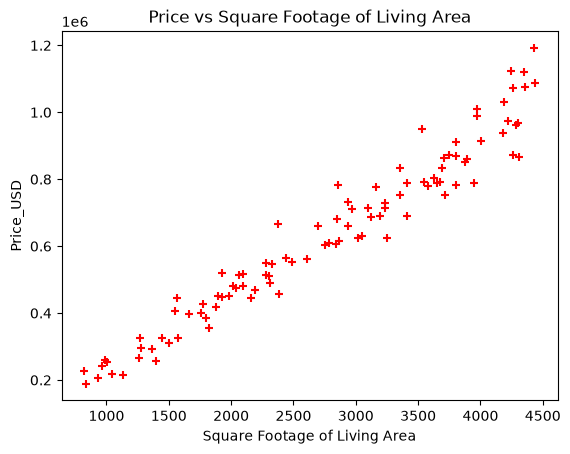

In [4]:
%matplotlib inline
plt.scatter(df['Area_SqFt'], df['Price_USD'], color='red', marker='+')
plt.xlabel('Square Footage of Living Area')
plt.ylabel('Price_USD')
plt.title('Price vs Square Footage of Living Area')
plt.show()

In [5]:
reg = linear_model.LinearRegression()
reg.fit(df[['Area_SqFt']], df['Price_USD'])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[232.47]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Area_SqFt']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7673
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


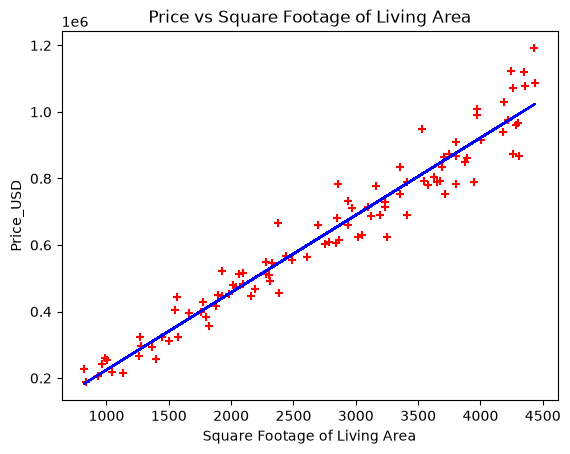

In [47]:
%matplotlib inline
plt.scatter(df['Area_SqFt'], df['Price_USD'], color='red', marker='+')
plt.plot(df[['Area_SqFt']], reg.predict(df[['Area_SqFt']]), color='blue')
plt.xlabel('Square Footage of Living Area')
plt.ylabel('Price_USD')
plt.title('Price vs Square Footage of Living Area')
plt.show()

In [23]:
reg.predict([[3300]])

C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([759473.78456337])

In [9]:
reg.coef_

array([232.46863577])

In [11]:
reg.intercept_

np.float64(-7672.713470655493)

In [14]:
y = reg.coef_ * 3300 + reg.intercept_
y

array([759473.78456337])

In [15]:
d = pd.read_csv(r"C:\Users\Lenovo\Downloads\property_data_with_area.csv")
d

,property_id,area_sqft,bedrooms,bathrooms,property_type,price_usd
0,PROP-1000,1360,2,1.5,Townhouse,321600.0
1,PROP-1001,1794,1,1.0,Townhouse,376300.0
2,PROP-1002,1630,4,3.2,Apartment,404900.0
3,PROP-1003,1595,3,1.9,Single Family,440800.0
4,PROP-1004,2138,3,2.4,Townhouse,490000.0
...,...,...,...,...,...,...
95,PROP-1095,2562,2,1.5,Condo,586600.0
96,PROP-1096,564,2,1.2,Condo,178700.0
97,PROP-1097,3068,1,1.0,Condo,641600.0
98,PROP-1098,1867,3,2.7,Apartment,394700.0


In [35]:
d.drop(columns=['property_id', 'bedrooms', 'bathrooms'], inplace=True)

In [37]:
d.drop(columns=['property_type'], inplace=True)

In [38]:
d

,area_sqft
0,1360
1,1794
2,1630
3,1595
4,2138
...,...
95,2562
96,564
97,3068
98,1867


In [42]:
p = d.rename(columns={"area_sqft": "Area_SqFt"})
p.head(3)

,Area_SqFt
0,1360
1,1794
2,1630


In [43]:
reg.predict(p[['Area_SqFt']])

array([308484.63117367, 409376.01909693, 371251.162831  , 363114.76057912,
       489345.22980108, 612786.07539383, 216891.98868112, 396357.77549393,
       185276.25421669, 453080.12262129, 604882.14177772, 787137.55221974,
       138782.52706311, 500271.25568217, 287329.98531879, 664394.1125343 ,
       460751.58760163, 771794.62225906, 674157.79523655, 391010.99687127,
       330569.15157162, 648818.71393785, 383804.46916246, 215264.70823075,
       113443.44576441, 643239.46667942, 282215.6753319 , 783650.52268323,
       218751.73776726, 360092.66831414, 703216.37470754, 584424.90183015,
       747152.94686767, 335218.52428698, 528399.96061009, 152498.17657342,
       744130.85460268, 239208.97771484, 550019.5437365 , 403099.3659312 ,
       777838.80678903, 463773.67986662, 258736.34311934, 589306.74318127,
       779931.02451094, 623247.16400338, 410073.42500423, 674622.73250809,
       248042.78587402, 657884.9907328 , 587679.4627309 , 164586.54563335,
       583030.09001554, 7

In [45]:
d['prices'] = reg.predict(p[['Area_SqFt']])

In [46]:
d.to_csv(r"C:\Users\Lenovo\Downloads\property_data_with_area_and_prices.csv", index=False)